# 01. Khám phá dữ liệu Student Performance

Notebook này được thực hiện để tìm hiểu bộ dữ liệu Student Performance trước khi xây dựng mô hình dự đoán điểm cuối kỳ (G3). Qua bước này, nhóm sẽ kiểm tra dữ liệu và xem các đặc điểm của bộ dữ liệu.

Trong notebook này nhóm thực hiện các công việc sau:

- Đọc và kiểm tra dữ liệu.
- Kiểm tra dữ liệu thiếu và dữ liệu trùng.
- Xem phân bố của điểm G3.
- Vẽ một số biểu đồ để quan sát mối liên hệ giữa các biến.

In [11]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

def find_project_root():
    current = Path.cwd().resolve()
    for folder in [current, *current.parents]:
        if (folder / 'data').exists() and (folder / 'src').exists():
            return folder
    raise FileNotFoundError('Không tìm thấy thư mục gốc của project.')

PROJECT_ROOT = find_project_root()
MERGED_FILE = PROJECT_ROOT / 'data' / 'interim' / 'merged.csv'
FIGURES_DIR = PROJECT_ROOT / 'artifacts' / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', 40)
print(f'Project root: {PROJECT_ROOT}')

Project root: C:\Users\NhatThien\Documents\GitHub\Nhom9-De18-student-performance-ml


In [12]:
# Đọc merged.csv. Nếu file trung gian chưa có, đọc trực tiếp hai file raw.
if MERGED_FILE.exists():
    df = pd.read_csv(MERGED_FILE)
else:
    raw_dir = PROJECT_ROOT / 'data' / 'raw'
    math_df = pd.read_csv(raw_dir / 'student-mat.csv', sep=';')
    math_df.insert(0, 'subject', 'math')
    portuguese_df = pd.read_csv(raw_dir / 'student-por.csv', sep=';')
    portuguese_df.insert(0, 'subject', 'portuguese')
    df = pd.concat([math_df, portuguese_df], ignore_index=True)

print(f'Kích thước dữ liệu: {df.shape[0]} dòng x {df.shape[1]} cột')
display(df.head())
display(df.dtypes.rename('dtype').to_frame())

Kích thước dữ liệu: 1044 dòng x 34 cột


,subject,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,math,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,math,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,math,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,math,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,math,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


,dtype
subject,str
school,str
sex,str
age,int64
address,str
famsize,str
Pstatus,str
Medu,int64
Fedu,int64
Mjob,str


In [13]:
# Kiểm tra chất lượng dữ liệu trước khi phân tích.
missing = df.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
print('Các cột có giá trị thiếu:')
display(missing.to_frame('missing_count') if not missing.empty else pd.DataFrame({'missing_count': [0]}, index=['Không có']))
print(f'Số dòng trùng hoàn toàn: {df.duplicated().sum()}')
print('Số dòng theo môn học:')
display(df['subject'].value_counts().rename('count').to_frame())

numeric_columns = df.select_dtypes(include='number').columns.tolist()
display(df[numeric_columns].describe().T)

Các cột có giá trị thiếu:


,missing_count
Không có,0


Số dòng trùng hoàn toàn: 0
Số dòng theo môn học:


,count
subject,
portuguese,649
math,395


,count,mean,std,min,25%,50%,75%,max
age,1044.0,16.726054,1.239975,15.0,16.0,17.0,18.0,22.0
Medu,1044.0,2.603448,1.124907,0.0,2.0,3.0,4.0,4.0
Fedu,1044.0,2.387931,1.099938,0.0,1.0,2.0,3.0,4.0
traveltime,1044.0,1.522989,0.731727,1.0,1.0,1.0,2.0,4.0
studytime,1044.0,1.970307,0.834353,1.0,1.0,2.0,2.0,4.0
failures,1044.0,0.264368,0.656142,0.0,0.0,0.0,0.0,3.0
famrel,1044.0,3.935824,0.933401,1.0,4.0,4.0,5.0,5.0
freetime,1044.0,3.201149,1.031507,1.0,3.0,3.0,4.0,5.0
goout,1044.0,3.156130,1.152575,1.0,2.0,3.0,4.0,5.0
Dalc,1044.0,1.494253,0.911714,1.0,1.0,1.0,2.0,5.0


In [14]:
# Thống kê điểm G3 theo môn học.
subject_summary = (
    df.groupby("subject")["G3"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

display(subject_summary)

print("Trung bình G3 theo thời gian học:")

display(
    df.groupby("studytime")["G3"]
    .mean()
    .round(2)
    .rename("mean_G3")
    .to_frame()
)

,count,mean,median,std,min,max
subject,,,,,,
math,395,10.42,11.0,4.58,0,20
portuguese,649,11.91,12.0,3.23,0,19


Trung bình G3 theo thời gian học:


,mean_G3
studytime,
1,10.58
2,11.34
3,12.49
4,12.27


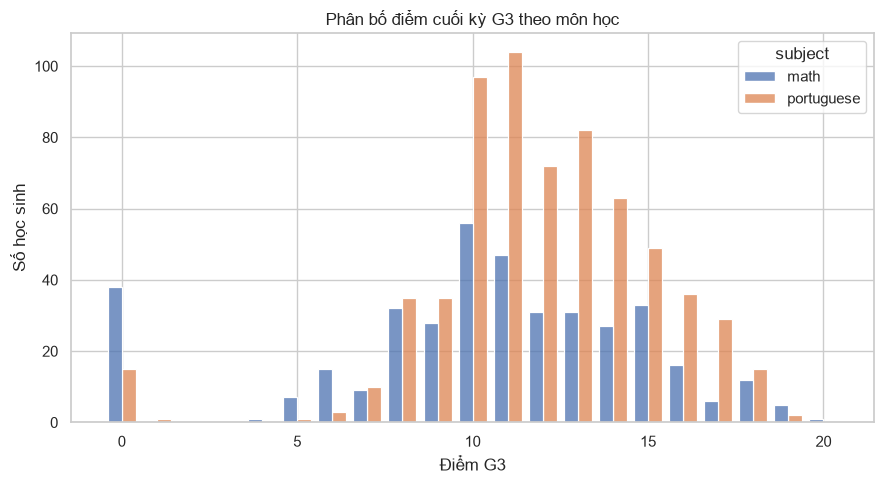

In [15]:
# Biểu đồ 1: phân bố điểm G3 theo môn học.
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=df, x='G3', hue='subject', discrete=True, multiple='dodge', shrink=0.8, ax=ax)
ax.set_title('Phân bố điểm cuối kỳ G3 theo môn học')
ax.set_xlabel('Điểm G3')
ax.set_ylabel('Số học sinh')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'eda_g3_distribution.png', dpi=150)
plt.show()

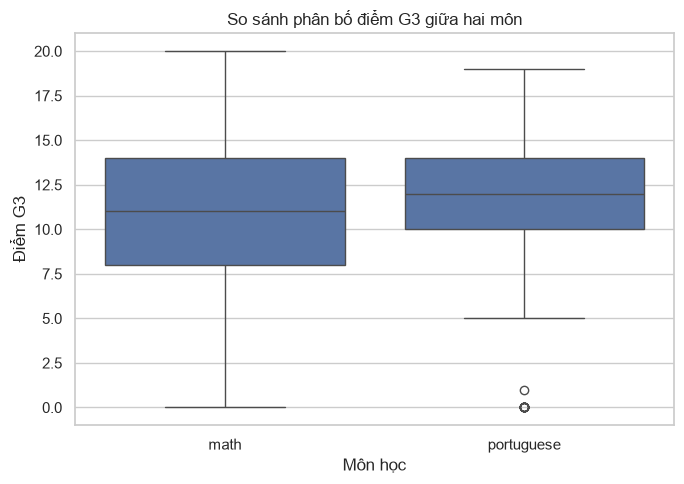

In [16]:
# Biểu đồ 2: so sánh điểm G3 giữa hai môn.
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=df, x='subject', y='G3', ax=ax)
ax.set_title('So sánh phân bố điểm G3 giữa hai môn')
ax.set_xlabel('Môn học')
ax.set_ylabel('Điểm G3')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'eda_g3_by_subject.png', dpi=150)
plt.show()

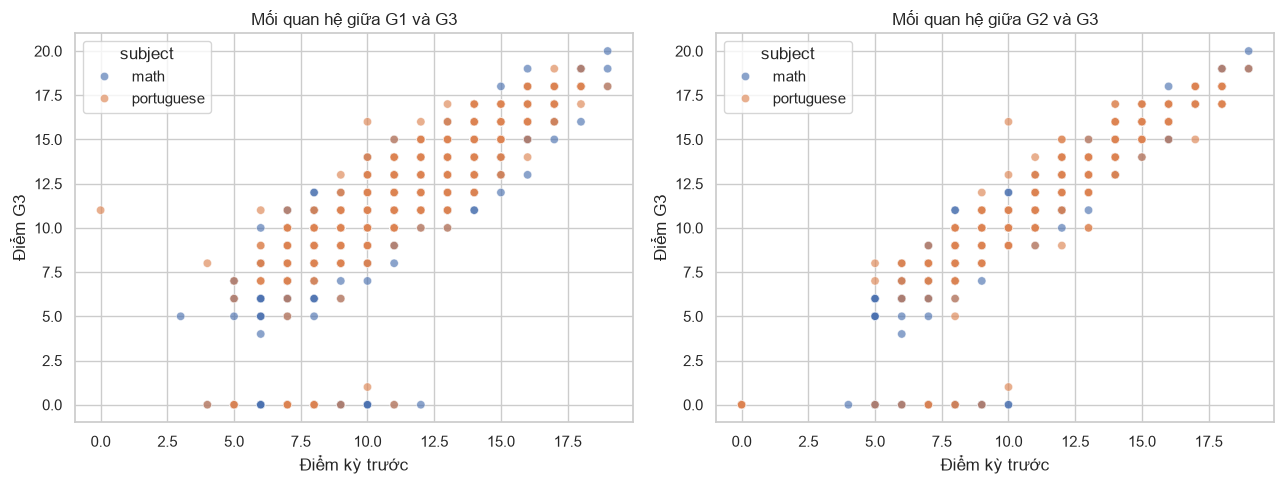

In [17]:
# Biểu đồ 3: điểm các kỳ trước và điểm cuối kỳ.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=df, x='G1', y='G3', hue='subject', alpha=0.65, ax=axes[0])
axes[0].set_title('Mối quan hệ giữa G1 và G3')
sns.scatterplot(data=df, x='G2', y='G3', hue='subject', alpha=0.65, ax=axes[1])
axes[1].set_title('Mối quan hệ giữa G2 và G3')
for ax in axes:
    ax.set_xlabel('Điểm kỳ trước')
    ax.set_ylabel('Điểm G3')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'eda_previous_grades_vs_g3.png', dpi=150)
plt.show()

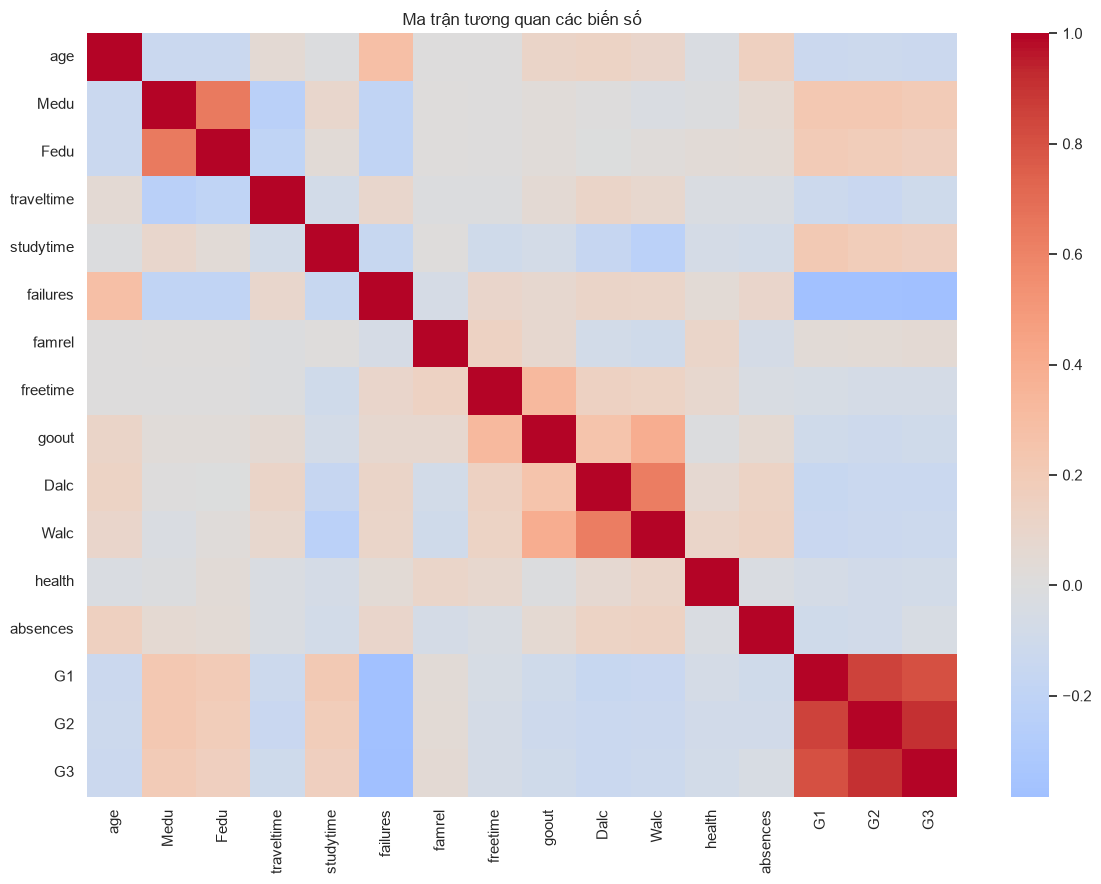

Tương quan với G3:


,correlation_with_G3
G3,1.000000
G2,0.910743
G1,0.809142
Medu,0.201472
studytime,0.161629
Fedu,0.159796
famrel,0.054461
absences,-0.045671
freetime,-0.064890
health,-0.080079


In [18]:
# Biểu đồ 4: ma trận tương quan của các biến số.
corr = df.select_dtypes(include='number').corr()
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corr, cmap='coolwarm', center=0, ax=ax)
ax.set_title('Ma trận tương quan các biến số')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'eda_numeric_correlation.png', dpi=150)
plt.show()

print('Tương quan với G3:')
display(corr['G3'].sort_values(ascending=False).to_frame('correlation_with_G3'))

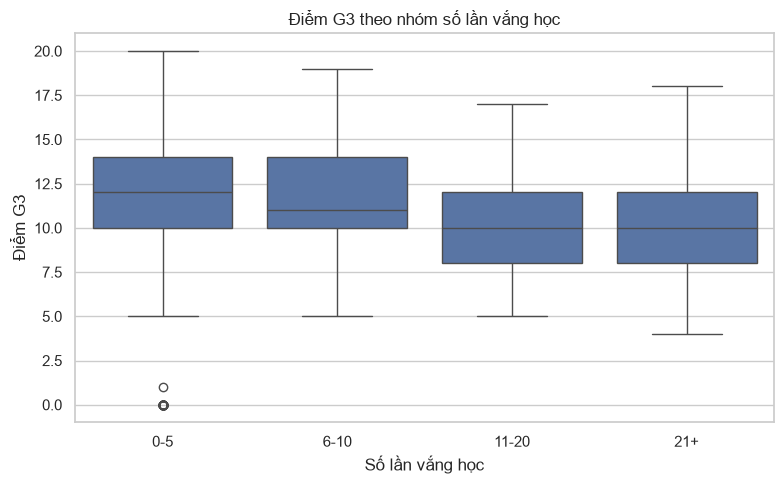

In [19]:
# Biểu đồ 5: số lần vắng học và điểm G3.
absence_bins = [-1, 5, 10, 20, 100]
absence_labels = ['0-5', '6-10', '11-20', '21+']
plot_df = df.assign(absence_group=pd.cut(df['absences'], bins=absence_bins, labels=absence_labels))
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=plot_df, x='absence_group', y='G3', ax=ax)
ax.set_title('Điểm G3 theo nhóm số lần vắng học')
ax.set_xlabel('Số lần vắng học')
ax.set_ylabel('Điểm G3')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'eda_absences_vs_g3.png', dpi=150)
plt.show()

In [20]:
# Lưu một số bảng tổng hợp để dùng lại trong báo cáo.
summary = {
    'rows': int(df.shape[0]),
    'columns': int(df.shape[1]),
    'subjects': {str(k): int(v) for k, v in df['subject'].value_counts().items()},
    'g3_mean': float(df['G3'].mean()),
    'g3_median': float(df['G3'].median()),
    'missing_values': int(df.isna().sum().sum()),
    'duplicate_rows': int(df.duplicated().sum())
}
(PROJECT_ROOT / 'artifacts' / 'eda_summary.json').write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8'
)
print('Đã lưu bảng và biểu đồ EDA vào artifacts/.')

Đã lưu bảng và biểu đồ EDA vào artifacts/.


## Kết luận

Notebook này giúp nhóm hiểu rõ hơn về bộ dữ liệu trước khi xây dựng mô hình. Dựa trên các bảng thống kê và biểu đồ, nhóm có thể lựa chọn các đặc trưng phù hợp cho những bước xử lý tiếp theo.